In [3]:
# Setup / importing libraries
import kagglehub
# import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/sleep_debt_screen_time.csv")

# Initial Data Exploration
print('\nData Types:\n',df.dtypes)
print('\nShape:', df.shape)
print('\nDescribe:')
display(df.describe())
print('\nHead:')
display(df.head())



Data Types:
 user_id                         int64
age                             int64
gender                         object
chronotype                     object
occupation                     object
bedtime_hour                  float64
screen_time_before_bed_min      int64
primary_app_category           object
screen_brightness_pct           int64
blue_light_filter_on             bool
caffeine_intake_mg              int64
caffeine_last_hour            float64
physical_activity_min           int64
room_temperature_f            float64
ambient_noise_db              float64
sleep_onset_latency_min       float64
total_sleep_hours             float64
rem_sleep_pct                 float64
deep_sleep_pct                float64
awakenings_count                int64
sleep_efficiency_pct          float64
next_day_fatigue_score        float64
sleep_debt_category            object
dtype: object

Shape: (8500, 23)

Describe:


,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,4250.500000,28.099647,13.883186,53.744118,68.770235,79.650000,15.905871,29.761882,70.083506,34.972753,31.396459,6.779473,16.925612,17.541812,2.328941,81.989035,4.549893
std,2453.882977,9.007551,10.836579,35.349292,18.923090,78.348824,3.844196,30.000228,3.962443,10.011726,8.710716,0.865113,2.426697,2.377407,1.619038,4.577948,0.954115
min,1.000000,16.000000,0.000000,5.000000,5.000000,0.000000,6.000000,0.000000,58.000000,10.000000,6.000000,3.910000,7.600000,9.100000,0.000000,59.600000,1.070000
25%,2125.750000,21.000000,1.090000,29.000000,56.000000,22.000000,13.200000,8.000000,67.400000,28.200000,25.500000,6.180000,15.300000,15.900000,1.000000,79.100000,3.890000
50%,4250.500000,27.000000,22.200000,45.000000,69.000000,55.500000,16.000000,20.000000,70.100000,35.000000,30.800000,6.770000,16.900000,17.500000,2.000000,82.200000,4.520000
75%,6375.250000,34.000000,23.150000,68.000000,83.000000,113.000000,18.700000,42.000000,72.700000,41.500000,36.700000,7.370000,18.600000,19.100000,3.000000,85.100000,5.180000
max,8500.000000,65.000000,24.000000,240.000000,100.000000,500.000000,23.000000,180.000000,82.000000,70.000000,75.200000,9.690000,27.300000,28.700000,11.000000,95.400000,8.850000



Head:


,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

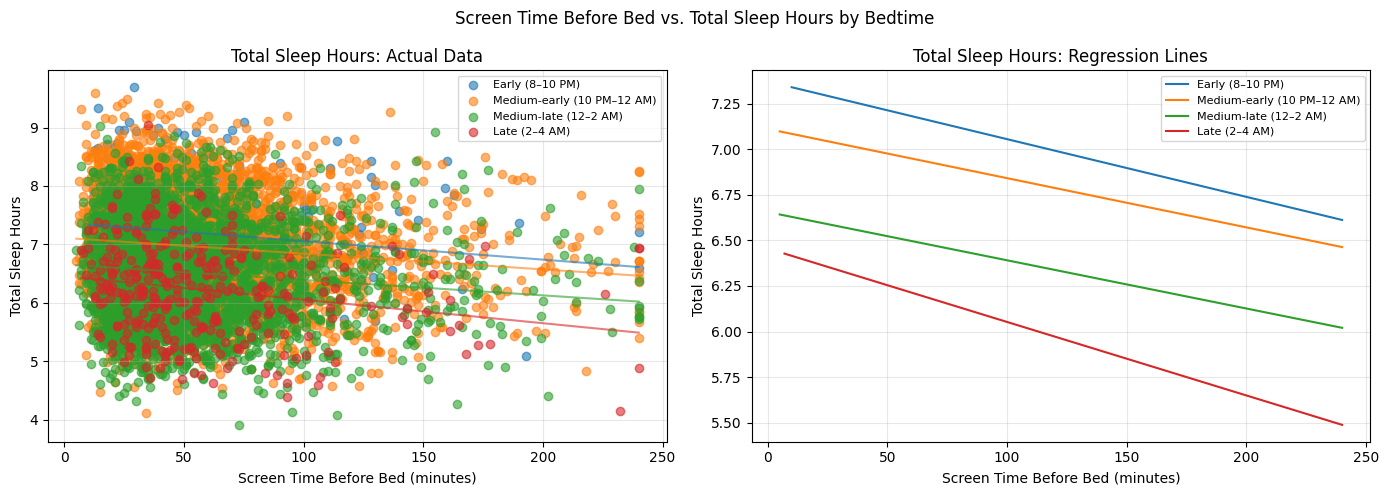

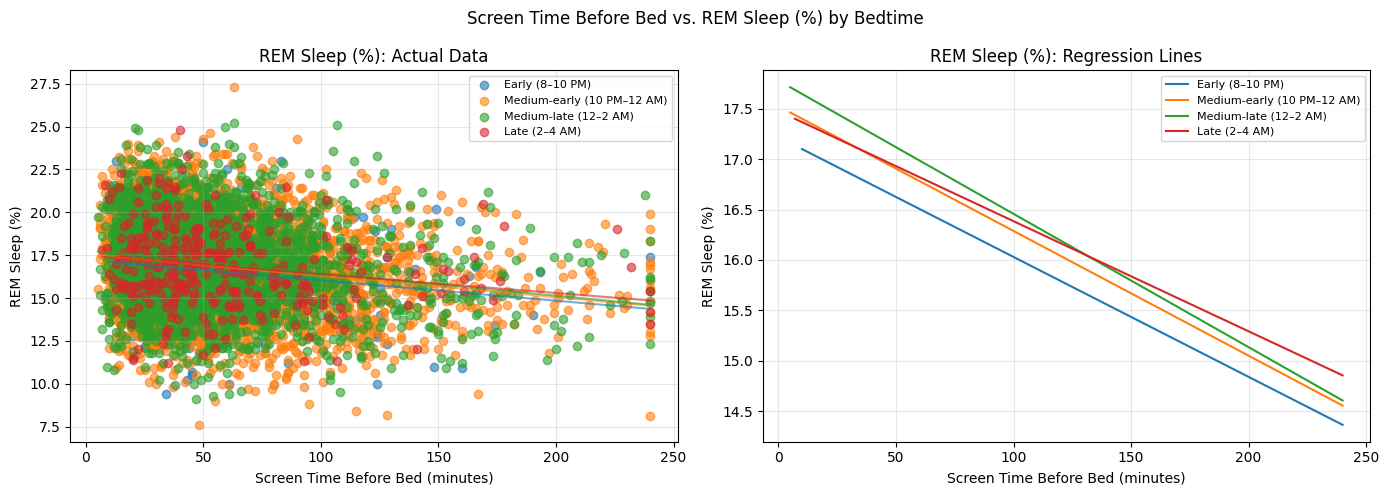

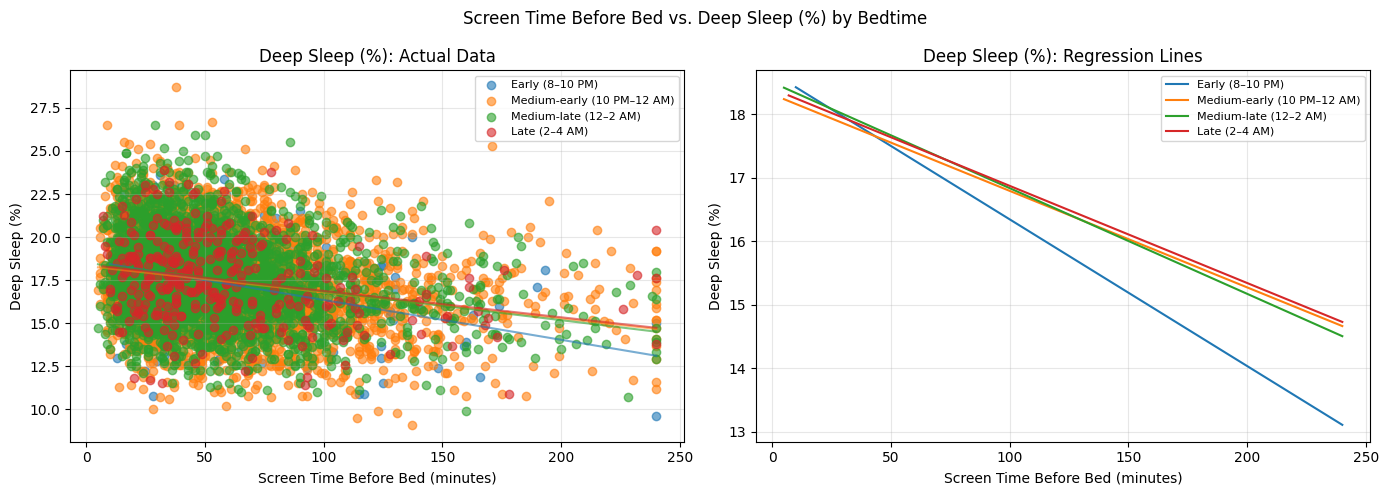

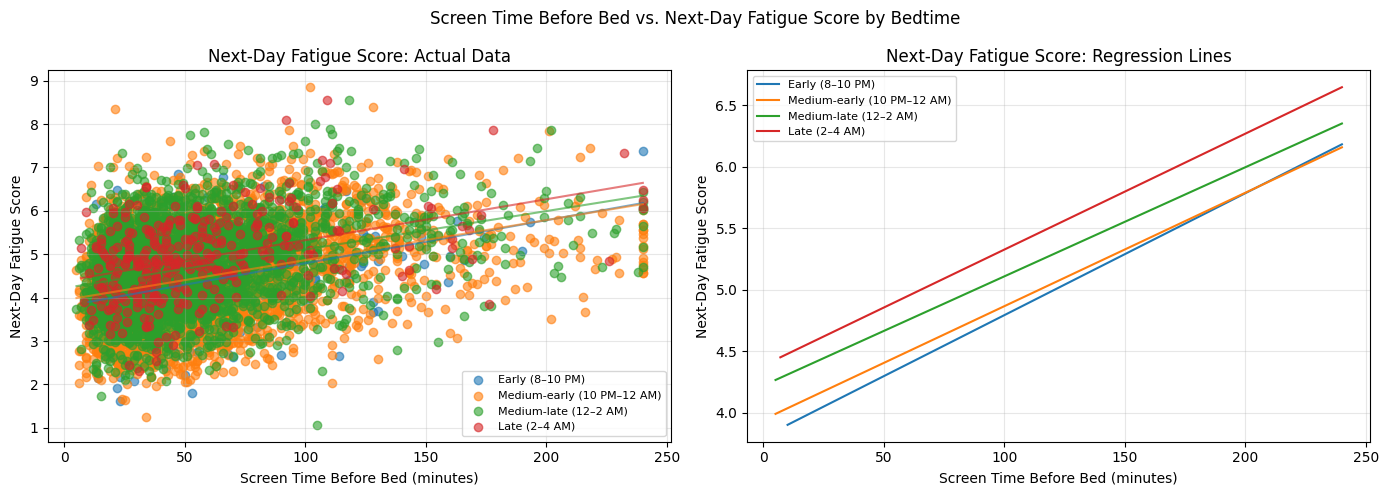

In [4]:
# Question 1: Does when you use screens matter more than total screen time?
# Hypothesis: Long periods of screen use have less of an impact on sleep when screen use occurs earlier in the night.


# Keep only the columns needed for this analysis.
sleep_df = df[[
    "bedtime_hour",
    "screen_time_before_bed_min",
    "total_sleep_hours",
    "rem_sleep_pct",
    "deep_sleep_pct",
    "next_day_fatigue_score"
]].copy()


# Divide bedtimes into four two-hour intervals.
# Using separate groups handles the transition from midnight (0) to the early morning hours.

early_df = sleep_df[
    (sleep_df["bedtime_hour"] >= 20) &
    (sleep_df["bedtime_hour"] < 22)
].copy()

medium_early_df = sleep_df[
    (sleep_df["bedtime_hour"] >= 22) &
    (sleep_df["bedtime_hour"] < 24)
].copy()

medium_late_df = sleep_df[
    (sleep_df["bedtime_hour"] >= 0) &
    (sleep_df["bedtime_hour"] < 2)
].copy()

late_df = sleep_df[
    (sleep_df["bedtime_hour"] >= 2) &
    (sleep_df["bedtime_hour"] < 4)
].copy()


# Store each bedtime group with a label for plotting.
bedtime_groups = {
    "Early (8–10 PM)": early_df,
    "Medium-early (10 PM–12 AM)": medium_early_df,
    "Medium-late (12–2 AM)": medium_late_df,
    "Late (2–4 AM)": late_df
}


# Define the sleep measurements to analyze.
sleep_metrics = [
    ("total_sleep_hours", "Total Sleep Hours"),
    ("rem_sleep_pct", "REM Sleep (%)"),
    ("deep_sleep_pct", "Deep Sleep (%)"),
    ("next_day_fatigue_score", "Next-Day Fatigue Score")
]

# Create two graphs side by side for each sleep measurement.
for y_column, y_label in sleep_metrics:

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for label, group in bedtime_groups.items():

        # Remove rows missing either variable.
        plot_data = group[
            ["screen_time_before_bed_min", y_column]
        ].dropna()

        x = plot_data["screen_time_before_bed_min"]
        y = plot_data[y_column]

        # Plot the actual data points.
        scatter = axes[0].scatter(
            x, y, label=label, alpha=0.6
        )

        # Calculate the regression line.
        if len(x) >= 2 and x.nunique() > 1:
            slope, intercept = np.polyfit(x, y, 1)

            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept

            # Match the line color to the group's points.
            axes[0].plot(
                x_line, y_line,
                color=scatter.get_facecolor()[0]
            )

    axes[0].set_title(f"{y_label}: Actual Data")
    axes[0].set_xlabel("Screen Time Before Bed (minutes)")
    axes[0].set_ylabel(y_label)
    axes[0].legend(fontsize=8)
    axes[0].grid(True, alpha=0.3)

    for label, group in bedtime_groups.items():

        # Remove rows missing either variable.
        plot_data = group[
            ["screen_time_before_bed_min", y_column]
        ].dropna()

        x = plot_data["screen_time_before_bed_min"]
        y = plot_data[y_column]

        # Calculate and plot a separate regression line.
        if len(x) >= 2 and x.nunique() > 1:
            slope, intercept = np.polyfit(x, y, 1)

            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept

            axes[1].plot(
                x_line, y_line,
                label=label
            )

    axes[1].set_title(f"{y_label}: Regression Lines")
    axes[1].set_xlabel("Screen Time Before Bed (minutes)")
    axes[1].set_ylabel(y_label)
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # Display both graphs side by side.
    plt.suptitle(
        f"Screen Time Before Bed vs. {y_label} by Bedtime"
    )
    plt.tight_layout()
    plt.show()